## 1. Libraries and dataset loading

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

classes = ['Lubrication', 'Electrical', 'Generator_Cooling']
all_labels = ['Normal'] + classes

def locate(stem, extension):
    paths = sorted(Path('/content').glob(stem + '*' + extension)) + sorted(Path('.').glob(stem + '*' + extension))
    unique = {str(p.resolve()): p for p in paths}
    if not unique:
        raise FileNotFoundError(f'Missing {stem}{extension}; add the original data files to the runtime')
    return sorted(unique.values(), key=lambda p: len(p.name))[0]

paths = {
    'Train': locate('SCADA_Train_All', '.xlsx'),
    'Validation': locate('SCADA_07_Validation', '.xlsx'),
    'Test': locate('SCADA_08_Test', '.xlsx'),
    'Features': locate('features_final', '.csv')
}
features = pd.read_csv(paths['Features'])['feature'].dropna().tolist()
assert len(features) == 48 and len(features) == len(set(features))
required = set(features) | {'Target', 'Fault_Type', 'Group_ID', 'Turbine_ID'}

def read_split(path):
    df = pd.read_excel(path, usecols=lambda x: x in required)
    assert required.issubset(df.columns), f'Missing columns: {required - set(df.columns)}'
    condition = df['Target'].eq(0) | (df['Target'].eq(1) & df['Fault_Type'].isin(classes))
    df = df.loc[condition].copy()
    df['Detection'] = np.where(df['Target'].eq(1), 'Fault', 'Normal')
    df['System_Label'] = np.where(df['Target'].eq(1), df['Fault_Type'], 'Normal')
    assert np.isfinite(df[features].to_numpy(dtype=float)).all(), 'Missing or infinite sensor values'
    return df.reset_index(drop=True)

train = read_split(paths['Train'])
val = read_split(paths['Validation'])
test = read_split(paths['Test'])
print('Files:', {k: str(v) for k,v in paths.items()})
print('Features:', len(features))
print('X train:', train.shape, '| X validation:', val.shape, '| X test:', test.shape)

Files: {'Train': 'SCADA_Train_All.xlsx', 'Validation': 'SCADA_07_Validation.xlsx', 'Test': 'SCADA_08_Test.xlsx', 'Features': 'features_final.csv'}
Features: 48
X train: (176172, 54) | X validation: (35620, 54) | X test: (35999, 54)


## 2. Data overview and class distribution

                    Train  Validation   Test
System_Label                                
Normal             154988       28292  33770
Lubrication         20068        7283   2185
Electrical            265          18     27
Generator_Cooling     851          27     17

Independent training fault groups:
Fault_Type
Electrical           15
Generator_Cooling     3
Lubrication           4
Name: Group_ID, dtype: int64

Training turbines by fault type:
Fault_Type
Electrical           8
Generator_Cooling    2
Lubrication          2
Name: Turbine_ID, dtype: int64


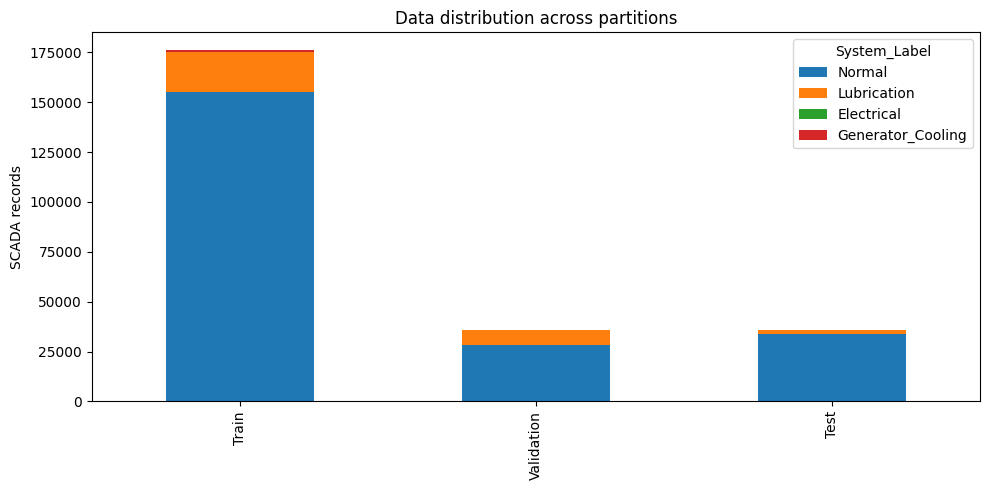

In [3]:
distribution = pd.DataFrame({
    name: data['System_Label'].value_counts().reindex(all_labels, fill_value=0)
    for name, data in [('Train', train), ('Validation', val), ('Test', test)]
})
print(distribution.to_string())
print('\nIndependent training fault groups:')
print(train.loc[train.Detection.eq('Fault')].groupby('Fault_Type')['Group_ID'].nunique())
print('\nTraining turbines by fault type:')
print(train.loc[train.Detection.eq('Fault')].groupby('Fault_Type')['Turbine_ID'].nunique())
distribution.T.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.title('Data distribution across partitions')
plt.ylabel('SCADA records')
plt.tight_layout()
plt.show()

## 3. Training-only controlled undersampling

In [4]:
fault_train = train.loc[train.Detection.eq('Fault')].copy()
lubrication = fault_train.loc[fault_train.Fault_Type.eq('Lubrication')]
other_faults = fault_train.loc[~fault_train.Fault_Type.eq('Lubrication')]
assert lubrication.Group_ID.notna().all()
sizes = lubrication.groupby('Group_ID').size()
amount = min(4000, len(lubrication))
ideal = sizes / sizes.sum() * amount
quotas = np.floor(ideal).astype(int)
remaining = amount - int(quotas.sum())
for group in (ideal - quotas).sort_values(ascending=False).index[:remaining]:
    quotas.loc[group] += 1
sampled_lubrication = pd.concat([
    lubrication.loc[lubrication.Group_ID.eq(group)].sample(n=int(count), random_state=42)
    for group, count in quotas.items() if count > 0
], ignore_index=True)
fault_sample = pd.concat([other_faults, sampled_lubrication], ignore_index=True).sample(frac=1, random_state=42)
normal_train = train.loc[train.Detection.eq('Normal')]
normal_sample = normal_train.sample(n=min(len(normal_train), 3 * len(fault_sample)), random_state=42)
detection_train = pd.concat([fault_sample, normal_sample], ignore_index=True).sample(frac=1, random_state=42)
class_counts = fault_sample['Fault_Type'].value_counts()
sqrt_weights = {label: float(np.sqrt(class_counts.max() / class_counts[label])) for label in classes}
print('Stage 1 training:', detection_train.Detection.value_counts().to_dict())
print('Stage 2 training:', class_counts.to_dict())
print('SVM class weights:', sqrt_weights)

Stage 1 training: {'Normal': 15348, 'Fault': 5116}
Stage 2 training: {'Lubrication': 4000, 'Generator_Cooling': 851, 'Electrical': 265}
SVM class weights: {'Lubrication': 1.0, 'Electrical': 3.885143449429057, 'Generator_Cooling': 2.1680296415038893}


## 4. Stage 1 — Random Forest and Isolation Forest comparison

In [5]:
rf_detection = RandomForestClassifier(n_estimators=250, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=-1, random_state=42)
rf_detection.fit(detection_train[features], detection_train.Detection)
rf_fault_index = list(rf_detection.classes_).index('Fault')
rf_val_scores = rf_detection.predict_proba(val[features])[:, rf_fault_index]

isolation = IsolationForest(n_estimators=200, max_samples=512, contamination='auto', n_jobs=-1, random_state=42)
isolation_normal = normal_train.sample(n=min(40000, len(normal_train)), random_state=42)
isolation.fit(isolation_normal[features])
isolation_val_scores = -isolation.score_samples(val[features])

stage1_candidates = []
for model_name, score, thresholds in [
    ('Random Forest', rf_val_scores, np.arange(0.05, 0.951, 0.05)),
    ('Isolation Forest', isolation_val_scores, np.unique(np.quantile(isolation_val_scores, np.linspace(0.65, 0.999, 45))))
]:
    for threshold_candidate in thresholds:
        pred = np.where(score >= threshold_candidate, 'Fault', 'Normal')
        stage1_candidates.append({
            'Model': model_name,
            'Threshold': float(threshold_candidate),
            'Accuracy': accuracy_score(val.Detection, pred),
            'Fault_Precision': precision_score(val.Detection, pred, pos_label='Fault', zero_division=0),
            'Fault_Recall': recall_score(val.Detection, pred, pos_label='Fault', zero_division=0),
            'Fault_F1': f1_score(val.Detection, pred, pos_label='Fault', zero_division=0),
            'Balanced_Accuracy': balanced_accuracy_score(val.Detection, pred)
        })

stage1_results = pd.DataFrame(stage1_candidates)
stage1_comparison = stage1_results.sort_values(['Fault_F1', 'Balanced_Accuracy'], ascending=False).groupby('Model', as_index=False).head(1).sort_values('Fault_F1', ascending=False).reset_index(drop=True)
print(stage1_comparison.round(4).to_string(index=False))
chosen_stage1 = stage1_comparison.iloc[0]
detection_model = rf_detection if chosen_stage1['Model'] == 'Random Forest' else isolation
detection_threshold = float(chosen_stage1['Threshold'])
print('\nStage 1 validation choice:', chosen_stage1['Model'], '| threshold:', round(detection_threshold, 5))

           Model  Threshold  Accuracy  Fault_Precision  Fault_Recall  Fault_F1  Balanced_Accuracy
   Random Forest     0.3000    0.9489           0.8575        0.9016    0.8790             0.9314
Isolation Forest     0.4436    0.5727           0.1835        0.3122    0.2312             0.4762

Stage 1 validation choice: Random Forest | threshold: 0.3


## 5. Stage 2 — Random Forest, XGBoost and SVM comparison

In [7]:
stage2_models = {
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', n_jobs=-1, random_state=42),
    'SVM RBF': SVC(kernel='rbf', C=5, gamma=0.01, class_weight=sqrt_weights, cache_size=500)
}
if HAS_XGBOOST:
    stage2_models['XGBoost'] = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', tree_method='hist', n_jobs=-1, random_state=42)
    from sklearn.preprocessing import LabelEncoder
    class_encoder = LabelEncoder().fit(classes)

val_faults = val.loc[val.Detection.eq('Fault')]
stage2_rows = []
for model_name, model in stage2_models.items():
    if model_name == 'XGBoost':
        # Convert to numpy array to avoid invalid feature names containing brackets [, ] or < in XGBoost
        model.fit(fault_sample[features].to_numpy(), class_encoder.transform(fault_sample.Fault_Type))
        pred = class_encoder.inverse_transform(model.predict(val_faults[features].to_numpy()).astype(int))
    else:
        model.fit(fault_sample[features], fault_sample.Fault_Type)
        pred = model.predict(val_faults[features])
    stage2_rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(val_faults.Fault_Type, pred),
        'Balanced_Accuracy': balanced_accuracy_score(val_faults.Fault_Type, pred),
        'Macro_F1': f1_score(val_faults.Fault_Type, pred, labels=classes, average='macro', zero_division=0)
    })
stage2_comparison = pd.DataFrame(stage2_rows).sort_values('Macro_F1', ascending=False)
print(stage2_comparison.round(4).to_string(index=False))
print('\nDeployed Stage 2: SVM RBF (C=5, gamma=0.01)')
svm = stage2_models['SVM RBF']
print('\nSVM validation classification report:')
print(classification_report(val_faults.Fault_Type, svm.predict(val_faults[features]), labels=classes, zero_division=0))

        Model  Accuracy  Balanced_Accuracy  Macro_F1
      SVM RBF    0.9967             0.8205    0.8070
      XGBoost    0.9969             0.7098    0.7835
Random Forest    0.9950             0.4444    0.5204

Deployed Stage 2: SVM RBF (C=5, gamma=0.01)

SVM validation classification report:
                   precision    recall  f1-score   support

      Lubrication       1.00      1.00      1.00      7283
       Electrical       0.62      0.83      0.71        18
Generator_Cooling       0.81      0.63      0.71        27

         accuracy                           1.00      7328
        macro avg       0.81      0.82      0.81      7328
     weighted avg       1.00      1.00      1.00      7328



## 6. Final Test — Stage 1, Stage 2 and end-to-end system

In [8]:
def detection_scores(model, data):
    if isinstance(model, IsolationForest):
        return -model.score_samples(data[features])
    fault_col = list(model.classes_).index('Fault')
    return model.predict_proba(data[features])[:, fault_col]

test_detection_score = detection_scores(detection_model, test)
stage1_pred = np.where(test_detection_score >= detection_threshold, 'Fault', 'Normal')
test_faults = test.loc[test.Detection.eq('Fault')]
stage2_pred = svm.predict(test_faults[features])
full_type_pred = svm.predict(test[features])
system_pred = np.where(stage1_pred == 'Fault', full_type_pred, 'Normal')

print('STAGE 1 — TEST')
print(classification_report(test.Detection, stage1_pred, labels=['Normal', 'Fault'], zero_division=0))
print('STAGE 2 — TEST ON TRUE FAULT SAMPLES')
print(classification_report(test_faults.Fault_Type, stage2_pred, labels=classes, zero_division=0))
print('END-TO-END SYSTEM — TEST')
print(classification_report(test.System_Label, system_pred, labels=all_labels, zero_division=0))

final_metrics = pd.DataFrame([
    {'Evaluation': 'Stage 1 detection', 'Accuracy': accuracy_score(test.Detection, stage1_pred), 'Balanced_Accuracy': balanced_accuracy_score(test.Detection, stage1_pred), 'F1': f1_score(test.Detection, stage1_pred, pos_label='Fault', zero_division=0), 'F1_Type': 'Fault F1'},
    {'Evaluation': 'Stage 2 classification', 'Accuracy': accuracy_score(test_faults.Fault_Type, stage2_pred), 'Balanced_Accuracy': balanced_accuracy_score(test_faults.Fault_Type, stage2_pred), 'F1': f1_score(test_faults.Fault_Type, stage2_pred, labels=classes, average='macro', zero_division=0), 'F1_Type': 'Macro F1'},
    {'Evaluation': 'End-to-end system', 'Accuracy': accuracy_score(test.System_Label, system_pred), 'Balanced_Accuracy': balanced_accuracy_score(test.System_Label, system_pred), 'F1': f1_score(test.System_Label, system_pred, labels=all_labels, average='macro', zero_division=0), 'F1_Type': 'Macro F1'}
])
print(final_metrics.round(4).to_string(index=False))

STAGE 1 — TEST
              precision    recall  f1-score   support

      Normal       0.94      0.93      0.94     33770
       Fault       0.02      0.02      0.02      2229

    accuracy                           0.88     35999
   macro avg       0.48      0.48      0.48     35999
weighted avg       0.88      0.88      0.88     35999

STAGE 2 — TEST ON TRUE FAULT SAMPLES
                   precision    recall  f1-score   support

      Lubrication       1.00      0.98      0.99      2185
       Electrical       1.00      0.56      0.71        27
Generator_Cooling       0.25      0.94      0.40        17

         accuracy                           0.97      2229
        macro avg       0.75      0.83      0.70      2229
     weighted avg       0.99      0.97      0.98      2229

END-TO-END SYSTEM — TEST
                   precision    recall  f1-score   support

           Normal       0.94      0.93      0.94     33770
      Lubrication       0.00      0.00      0.00      2185
  

## 7. Confusion matrices and comparison figures

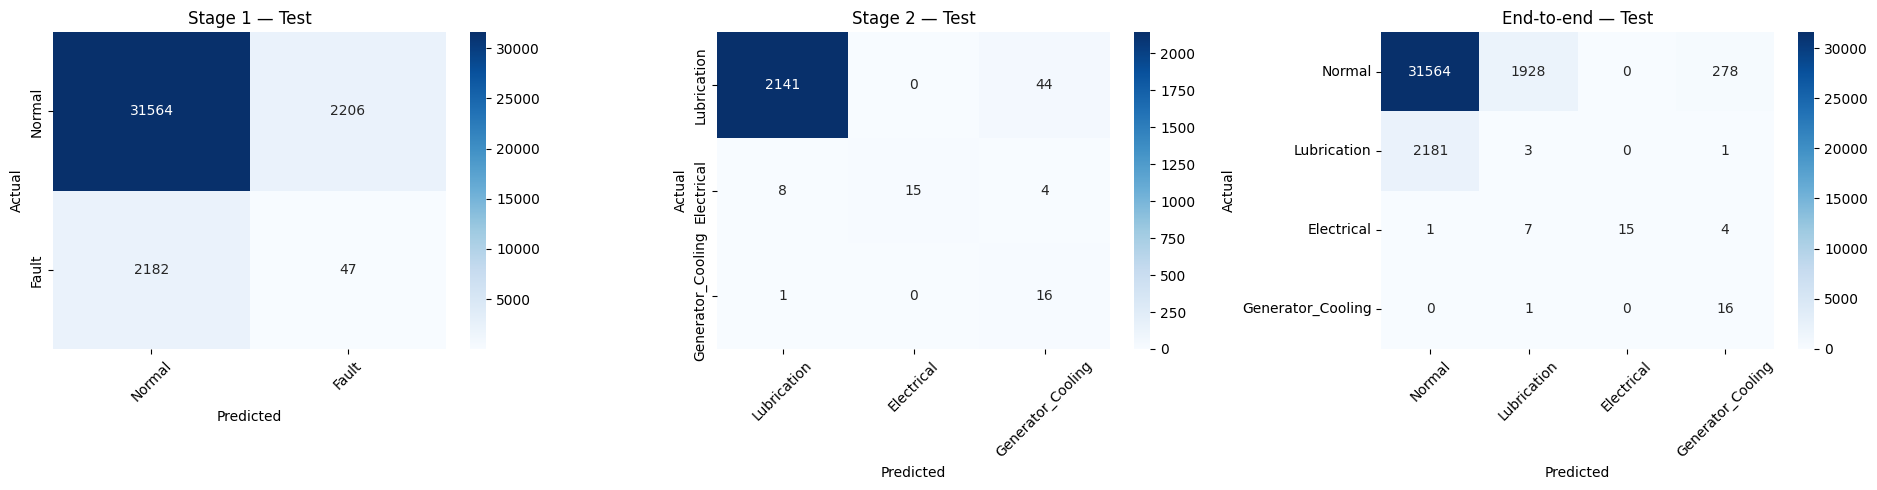

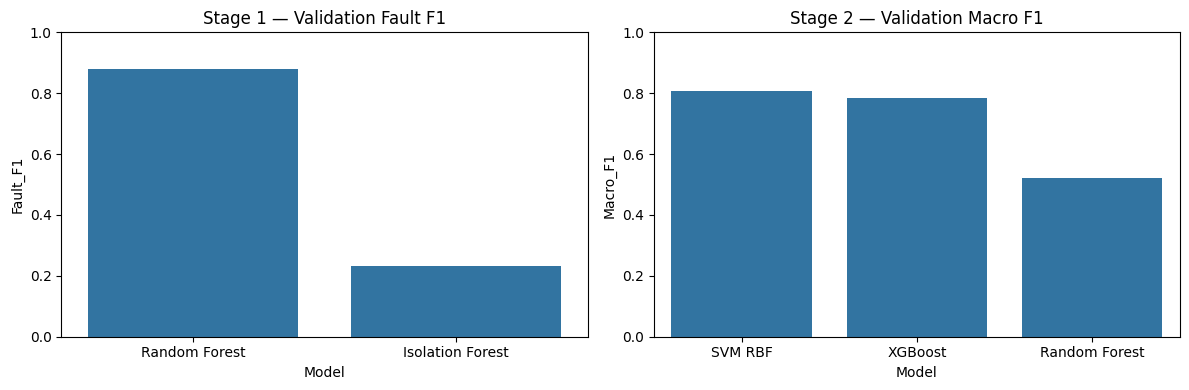

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
matrices = [
    (test.Detection, stage1_pred, ['Normal', 'Fault'], 'Stage 1 — Test'),
    (test_faults.Fault_Type, stage2_pred, classes, 'Stage 2 — Test'),
    (test.System_Label, system_pred, all_labels, 'End-to-end — Test')
]
for ax, (true, pred, labels, title) in zip(axes, matrices):
    sns.heatmap(confusion_matrix(true, pred, labels=labels), annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('SCADA_Final_Confusion_Matrices.png', dpi=160, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=stage1_comparison, x='Model', y='Fault_F1', ax=axes[0])
axes[0].set_title('Stage 1 — Validation Fault F1')
axes[0].set_ylim(0, 1)
sns.barplot(data=stage2_comparison, x='Model', y='Macro_F1', ax=axes[1])
axes[1].set_title('Stage 2 — Validation Macro F1')
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.savefig('SCADA_Model_Comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## 8. Turbine-level error analysis

In [10]:
audit = test[['Turbine_ID', 'Group_ID', 'Detection', 'System_Label']].copy()
audit['Stage1_Predicted'] = stage1_pred
audit['System_Predicted'] = system_pred
audit['Stage1_Correct'] = audit.Detection.eq(audit.Stage1_Predicted)
audit['System_Correct'] = audit.System_Label.eq(audit.System_Predicted)
print('Per-turbine accuracy and sample counts:')
print(audit.groupby('Turbine_ID').agg(Records=('System_Correct', 'size'), Detection_Accuracy=('Stage1_Correct', 'mean'), System_Accuracy=('System_Correct', 'mean')).round(4).to_string())
print('\nFault recall per turbine and fault type:')
print(audit.loc[audit.Detection.eq('Fault')].groupby(['Turbine_ID', 'System_Label']).Stage1_Correct.agg(['size', 'mean']).to_string())

Per-turbine accuracy and sample counts:
            Records  Detection_Accuracy  System_Accuracy
Turbine_ID                                              
WT01            969              1.0000           1.0000
WT02           3094              0.5782           0.5776
WT03           2870              0.9045           0.9038
WT04           2941              0.9745           0.9735
WT05           3232              0.9950           0.9950
WT06           7845              0.7137           0.7133
WT07           2975              0.9973           0.9963
WT08           5363              0.9961           0.9961
WT09            444              0.0315           0.0315
WT10           6266              0.9979           0.9979

Fault recall per turbine and fault type:
                              size      mean
Turbine_ID System_Label                     
WT02       Electrical            3  1.000000
           Generator_Cooling    17  1.000000
WT03       Electrical            8  1.000000
WT04     

## 9. Export final results and models

In [11]:
joblib.dump({
    'detector': detection_model,
    'detection_model_name': chosen_stage1['Model'],
    'detection_threshold': detection_threshold,
    'classifier': svm,
    'features': features,
    'fault_classes': classes,
    'sqrt_class_weights': sqrt_weights
}, 'SCADA_Final_TwoStage_Model.joblib')
stage1_comparison.to_csv('SCADA_Stage1_Model_Comparison.csv', index=False)
stage2_comparison.to_csv('SCADA_Stage2_Model_Comparison.csv', index=False)
final_metrics.to_csv('SCADA_Final_Test_Metrics.csv', index=False)
audit.to_csv('SCADA_Test_Predictions.csv', index=False)
print('All model artifacts and evaluation tables saved.')

All model artifacts and evaluation tables saved.
